# 03 · Generación de valor e insights

**Taller 2 – MINE-4101 Ciencia de Datos Aplicada (2026-20)**
Caso: FinAlpes – prueba de concepto de una herramienta de predicción de abandono (*churn*) de clientes bancarios.

Este notebook cubre los entregables **5 (20 %) Generación de valor** y **6 (10 %) Insights**:

1. Supuestos del caso de negocio, con sus fuentes.
2. Cómo pasar del dataset (20,4 % de abandono) a un banco promedio (15 %).
3. Ganancia de la campaña con y sin modelo, y elección del umbral que maximiza la ganancia.
4. **Ganancia esperada por cada estimación** (por cliente evaluado).
5. Inversión en el modelo y **punto de equilibrio** (*break-even*).
6. Análisis de sensibilidad paramétrico y simulación de Monte Carlo.
7. Limitaciones.
8. Insights y recomendación final.

**Entrada:** `data/processed/predicciones.csv` (salida del notebook 02: probabilidades de la regresión logística y del árbol en entrenamiento, validación y prueba).

> **Regla para no hacer trampa con los datos:** igual que en el notebook 02, todo lo que se *elige* (el umbral de decisión) se elige en **validación**, y los resultados económicos se reportan en **prueba**, que el modelo nunca vio.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "font.size": 10,
})
C_LR, C_DT = "#2a78d6", "#eb6834"          # regresión logística / árbol
C_GRIS, C_NEGRO = "#8a8984", "#0b0b0b"

DATA_DIR = Path("../data")
PROC_DIR = DATA_DIR / "processed"
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)


def mill(x, dec=1):
    """Millones de COP con formato colombiano: -154012345 -> '−$154,0 M'."""
    s = f"{abs(x) / 1e6:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{'−' if x < 0 else ''}${s} M"


def cop(x):
    """Pesos con separador de miles colombiano: 39231 -> '$39.231'."""
    return f"{'−' if x < 0 else ''}$" + f"{abs(x):,.0f}".replace(",", ".")


def tex(s):
    """Escapa '$' para que matplotlib no lo interprete como fórmula."""
    return s.replace("$", r"\$")


fmt_m = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}")

In [2]:
pred = pd.read_csv(PROC_DIR / "predicciones.csv")
val, test = pred[pred.split == "val"], pred[pred.split == "test"]
pred.groupby("split").agg(clientes=("churn", "size"), tasa_churn=("churn", "mean"),
                          p_lr_media=("p_lr", "mean"), p_dt_media=("p_dt", "mean")).loc[["train", "val", "test"]]

,clientes,tasa_churn,p_lr_media,p_dt_media
split,,,,
train,6000,0.20,0.40,0.39
val,2000,0.20,0.40,0.39
test,2000,0.20,0.39,0.39


Los dos modelos dan una probabilidad media de ≈ 0,39, casi el doble de la tasa real de abandono (≈ 0,20). No es un error: se entrenaron con `class_weight="balanced"`, que los hace "creer" que la mitad de los clientes abandona. Para calcular dinero hay que **recalibrar** esas probabilidades (sección 4). Para elegir a quién contactar basta con el **orden** que dan, que no cambia.

## 1. Supuestos del caso de negocio

La campaña funciona así: el modelo puntúa a todos los clientes, se contacta a los que superan un umbral de riesgo y se les hace una oferta de retención. **Se paga por cada cliente contactado**, abandone o no, pero la oferta **solo convence al 30 % de los que sí iban a abandonar**. Un cliente retenido conserva el ingreso anual que el banco habría perdido.

$$\text{Ganancia de la campaña} = \underbrace{VP \cdot s \cdot R \cdot H}_{\text{ingreso retenido}} \;-\; \underbrace{(VP + FP)\cdot c}_{\text{costo de contactar}}$$

donde $VP$ son los clientes contactados que iban a abandonar (verdaderos positivos), $FP$ los contactados que se iban a quedar (falsos positivos), $s$ la tasa de éxito de la oferta, $R$ el ingreso anual por cliente, $H$ los años de ingreso que se cuentan y $c$ el costo por contacto. Los clientes que abandonan sin ser contactados (falsos negativos) no suman ni restan frente a no hacer nada: ese ingreso se pierde de todas formas.

| Parámetro | Valor base | Rango para sensibilidad | Fuente o justificación |
|---|---|---|---|
| Clientes del banco ($N$) | 20.000 | 5.000 – 100.000 | Enunciado del taller. |
| Tasa de abandono anual ($\pi$) | **15 %** | 10 % – 20 % | Enunciado: tasa promedio de deserción en banca minorista ([Business Weekly](https://businessweekly.co.bw/?p=269584)). El dataset tiene 20,4 % y se corrige (sección 2). |
| Éxito de la oferta ($s$) | **30 %** de los que iban a abandonar | 20 % – 40 % | Enunciado. |
| Ingreso anual por cliente activo ($R$) | **COP 700.000** | 500.000 – 900.000 | Enunciado (neobancos de la región, [Nu Holdings 6-K, mayo 2026](https://www.sec.gov/Archives/edgar/data/1691493/000129281426003055/nu20260514_6k.htm)). Control: el ARPAC de Nu en el 1T-2026 fue USD 15,9/mes ([6-K 2T-2026](https://www.sec.gov/Archives/edgar/data/0001691493/000129281426004222/nupr2q26_6k.htm)) ≈ COP 614.000/año, dentro del rango. Se usa el punto medio. |
| Años de ingreso de un cliente retenido ($H$) | **1 año** | 1 – 2 años | Supuesto conservador: solo se cuenta el ingreso del año siguiente. |
| TRM | COP 3.220 por USD | — | TRM del 5-nov-2026: COP 3.221,19 ([dolarhoy](https://www.dolarhoy.co/2026-11-05)). |
| **Costo por contacto ($c$)** | **≈ COP 39.200** | 20.000 – 60.000 | Suma de tres partes (abajo). |
| · Llamada de call center | ≈ COP 9.100 | | Tarifa de un agente *nearshore* en Colombia: USD 12–22 por hora, todo incluido ([FusionCX 2026](https://www.fusioncx.com/blog/locations/colombia/colombia-call-center-costs/), [Connext](https://connextglobal.com/outsourcing-in-bogota-colombia/)). Se usan USD 17/h × 10 min por cliente (llamada, reintentos y registro en CRM). |
| · SMS de aviso | ≈ COP 110 | | USD 0,0335 por SMS en Colombia, promedio ponderado ([Sent.dm, mar-2026](https://sent.dm/en/resources/sms-pricing/colombia-sms-pricing)). |
| · Incentivo de retención | COP 30.000 | | Supuesto: p. ej. exoneración de cuotas de manejo o un bono, ≈ 4 % del ingreso anual. La literatura de churn usa por defecto un incentivo de 5 % del valor del cliente ([empulse](https://empulse.readthedocs.io/en/latest/reference/generated/empulse.metrics.expected_cost_loss_churn.html)). Se entrega a **todos** los contactados (enunciado). |
| **Costo de implementación ($F$)** | **≈ COP 102,5 M** (una vez) | 60 – 160 M | 2 personas (científico de datos e ingeniero de datos/ML) × 5 meses (pasar de prueba de concepto a producción toma 4–6 meses, [The Neural Base](https://theneuralbase.com/ai-roi-measurement/learn/intermediate/retention-improvements/)) × COP 5,5 M/mes (salario medio de un científico de datos en Colombia, [KeepCoding, nov-2025](https://keepcoding.io/blog/salario-de-data-scientist-en-colombia/)) × 1,5 de carga prestacional (supuesto) + COP 20 M de integración con el CRM y despliegue. |
| **Costo de operación ($O$)** | **≈ COP 42,8 M al año** | 25 – 60 M | Nube y almacenamiento COP 1,5 M/mes (supuesto; una base de 20.000 clientes es mucho menor que los 1–10 M de registros para los que se citan USD 3.500–7.500/mes) + 25 % del tiempo de un científico de datos para monitoreo y reentrenamiento. |
| Frecuencia | 1 campaña al año sobre toda la base | — | Simplificación coherente con una tasa de abandono y un ingreso anuales. |

In [3]:
TRM = 3_220                       # COP por USD (TRM 5-nov-2026: 3.221,19)

# Costo por cliente contactado
tarifa_agente_usd_h = 17          # call center nearshore en Colombia: USD 12–22 por hora-agente, todo incluido
minutos_por_contacto = 10         # llamada + reintentos + registro en CRM
sms_usd = 0.0335                  # SMS en Colombia, promedio ponderado (Sent.dm, mar-2026)
incentivo = 30_000                # oferta de retención (≈ 4 % del ingreso anual)
costo_llamada = tarifa_agente_usd_h * minutos_por_contacto / 60 * TRM
costo_sms = sms_usd * TRM

# Inversión única y operación anual del modelo
salario_ds = 5_500_000            # salario medio de un científico de datos en Colombia (COP/mes)
factor_prestacional = 1.5         # prestaciones sociales, seguridad social y parafiscales
personas, meses_desarrollo = 2, 5
integracion = 20_000_000          # integración con el CRM, despliegue y pruebas
nube_mes = 1_500_000
dedicacion_mantenimiento = 0.25   # fracción de un científico de datos

SUP = {
    "N": 20_000,                  # clientes del banco
    "churn": 0.15,                # tasa de abandono anual del banco
    "exito": 0.30,                # fracción de los que iban a abandonar que la oferta retiene
    "ingreso": 700_000,           # ingreso anual por cliente activo (COP)
    "horizonte": 1,               # años de ingreso que se cuentan por cliente retenido
    "costo_contacto": costo_llamada + costo_sms + incentivo,
    "costo_impl": personas * meses_desarrollo * salario_ds * factor_prestacional + integracion,
    "costo_oper": 12 * (nube_mes + dedicacion_mantenimiento * salario_ds * factor_prestacional),
}

pd.Series({
    "Costo por contacto · llamada": costo_llamada,
    "Costo por contacto · SMS": costo_sms,
    "Costo por contacto · incentivo": incentivo,
    "Costo por contacto · TOTAL": SUP["costo_contacto"],
    "Valor de retener a un cliente que iba a abandonar (s·R·H)": SUP["exito"] * SUP["ingreso"] * SUP["horizonte"],
    "Ingreso en riesgo al año (N·π·R)": SUP["N"] * SUP["churn"] * SUP["ingreso"],
    "Costo de implementación (una vez)": SUP["costo_impl"],
    "Costo de operación (anual)": SUP["costo_oper"],
}, name="COP").map(cop).to_frame()

,COP
Costo por contacto · llamada,$9.123
Costo por contacto · SMS,$108
Costo por contacto · incentivo,$30.000
Costo por contacto · TOTAL,$39.231
Valor de retener a un cliente que iba a abandonar (s·R·H),$210.000
Ingreso en riesgo al año (N·π·R),$2.100.000.000
Costo de implementación (una vez),$102.500.000
Costo de operación (anual),$42.750.000


**Una cuenta que explica todo el caso.** Contactar a un cliente cuesta ≈ COP 39.200. Si ese cliente iba a abandonar, la oferta lo retiene con probabilidad 30 % y salva COP 700.000: en promedio vale COP 210.000. Por lo tanto, **contactar a alguien solo es rentable si su probabilidad de abandonar supera 39.200 / 210.000 ≈ 18,7 %**. Como la tasa promedio del banco es 15 %, **contactar a todos pierde dinero**: el negocio depende de que el modelo encuentre a los clientes con riesgo por encima de ese 18,7 %.

## 2. Del dataset al banco: ajuste de la tasa de abandono

El modelo se evaluó en un conjunto de prueba con **20,4 %** de abandono, pero el banco objetivo tiene **15 %**. No se pueden usar directamente la precisión ni el número de aciertos de la prueba, porque ambos dependen de esa tasa.

Lo que **sí** se puede trasladar son dos tasas que no dependen de la proporción de clases, sino solo de cómo el modelo puntúa a cada grupo:

- **Tasa de verdaderos positivos (TPR = recall):** de los clientes que abandonan, qué fracción supera el umbral.
- **Tasa de falsos positivos (FPR):** de los clientes que se quedan, qué fracción supera el umbral.

Con ellas, en el banco de 20.000 clientes:

$$VP = N \cdot \pi \cdot TPR \qquad FP = N \cdot (1-\pi)\cdot FPR$$

El supuesto detrás es que los clientes que abandonan (y los que se quedan) en el banco se parecen a los del dataset, y que solo cambia **cuántos** hay de cada tipo (*label shift*). La sección 7 discute esta limitación.

In [4]:
UMBRALES = np.round(np.arange(0.01, 1.00, 0.01), 2)


def tasas(y, p, u):
    """TPR (recall) y FPR del modelo con umbral u."""
    y, contactar = np.asarray(y), np.asarray(p) >= u
    return contactar[y == 1].mean(), contactar[y == 0].mean()


def economia(tpr, fpr, **cambios):
    """Resultado de una campaña en el banco. `cambios` reemplaza supuestos de SUP."""
    s = {**SUP, **cambios}
    vp = s["N"] * s["churn"] * tpr
    fp = s["N"] * (1 - s["churn"]) * fpr
    ingreso = vp * s["exito"] * s["ingreso"] * s["horizonte"]
    costo = (vp + fp) * s["costo_contacto"]
    return {"contactados": vp + fp, "VP": vp, "FP": fp, "retenidos": vp * s["exito"],
            "ingreso retenido": ingreso, "costo campaña": costo, "ganancia campaña": ingreso - costo}


def curva(y, p, **cambios):
    """Resultado de la campaña para cada umbral."""
    return pd.DataFrame([{"umbral": u, **economia(*tasas(y, p, u), **cambios)} for u in UMBRALES]).set_index("umbral")


def umbral_optimo(y, p, **cambios):
    return curva(y, p, **cambios)["ganancia campaña"].idxmax()

## 3. Ganancia de la campaña: con y sin modelo

### 3.1 Umbral que maximiza la ganancia

En el notebook 02 se usó el umbral 0,5, que es arbitrario. Aquí se elige el umbral que **maximiza la ganancia en validación** y luego se mide en prueba.

Umbral que maximiza la ganancia en validación:  regresión logística = 0.57  |  árbol = 0.58


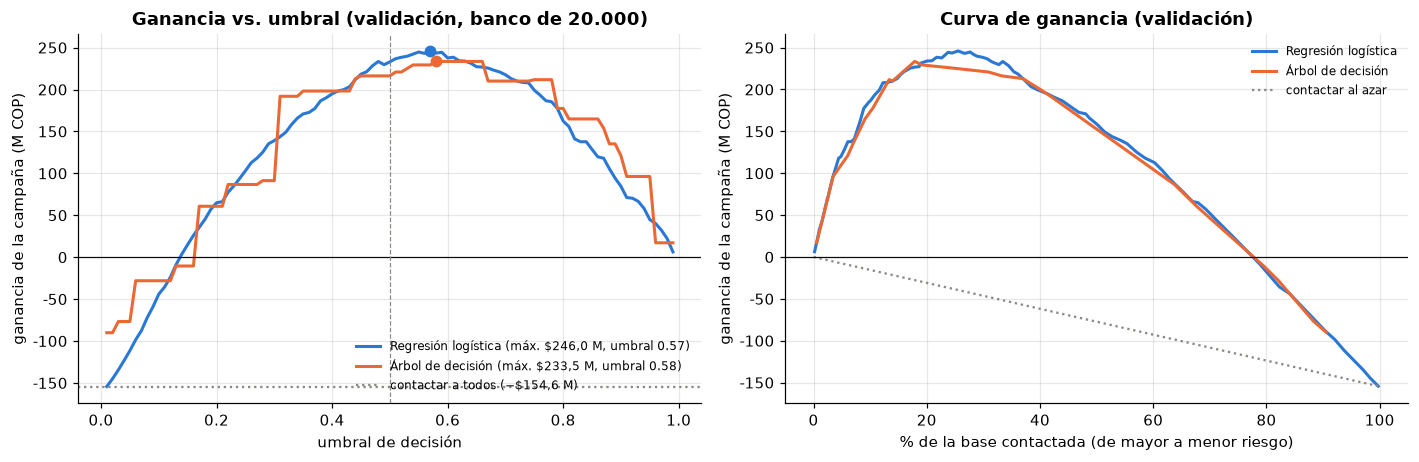

In [5]:
u_lr = umbral_optimo(val.churn, val.p_lr)
u_dt = umbral_optimo(val.churn, val.p_dt)
c_lr, c_dt = curva(val.churn, val.p_lr), curva(val.churn, val.p_dt)
todos = economia(1, 1)["ganancia campaña"]
print(f"Umbral que maximiza la ganancia en validación:  regresión logística = {u_lr:.2f}  |  árbol = {u_dt:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for c, col, lab, u in [(c_lr, C_LR, "Regresión logística", u_lr), (c_dt, C_DT, "Árbol de decisión", u_dt)]:
    g = c.loc[u, "ganancia campaña"]
    ax.plot(c.index, c["ganancia campaña"], color=col, lw=2, label=tex(f"{lab} (máx. {mill(g)}, umbral {u:.2f})"))
    ax.scatter(u, g, color=col, s=45, zorder=3)
ax.axhline(todos, color=C_GRIS, ls=":", lw=1.5, label=tex(f"contactar a todos ({mill(todos)})"))
ax.axhline(0, color=C_NEGRO, lw=0.8)
ax.axvline(0.5, color=C_GRIS, ls="--", lw=0.8)
ax.yaxis.set_major_formatter(fmt_m)
ax.set(xlabel="umbral de decisión", ylabel="ganancia de la campaña (M COP)",
       title="Ganancia vs. umbral (validación, banco de 20.000)")
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[1]
for c, col, lab in [(c_lr, C_LR, "Regresión logística"), (c_dt, C_DT, "Árbol de decisión")]:
    ax.plot(c["contactados"] / SUP["N"] * 100, c["ganancia campaña"], color=col, lw=2, label=lab)
x = np.linspace(0, 100, 51)
ax.plot(x, [economia(f / 100, f / 100)["ganancia campaña"] for f in x], color=C_GRIS, ls=":", lw=1.5, label="contactar al azar")
ax.axhline(0, color=C_NEGRO, lw=0.8)
ax.yaxis.set_major_formatter(fmt_m)
ax.set(xlabel="% de la base contactada (de mayor a menor riesgo)", ylabel="ganancia de la campaña (M COP)",
       title="Curva de ganancia (validación)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_ganancia_umbral.png", bbox_inches="tight"); plt.show()

**Lectura**

- El umbral que maximiza la ganancia en validación es **0,57 para la regresión logística** y **0,58 para el árbol**, más alto que el 0,5 del notebook 02. La razón es la cuenta de la sección 1: con un banco al 15 % de abandono, contactar solo compensa si el riesgo real del cliente supera 18,7 %, y eso exige ser más selectivo.
- La curva de la regresión logística es **plana cerca del máximo**: entre los umbrales 0,45 y 0,65 la ganancia se mantiene entre ≈ COP 215 M y 246 M. Equivocarse un poco en el umbral cuesta poco.
- El árbol avanza a **escalones** porque solo produce 27 probabilidades distintas (una por hoja). Eso impide ajustar con precisión el número de clientes a contactar.
- **Curva de ganancia (derecha).** La ganancia sube rápido al contactar al primer 20–25 % de la base (los de mayor riesgo), llega al máximo y luego baja: desde ahí cada contacto adicional cuesta más de lo que recupera. Si se contacta a más del ≈ 78 % de la base, la campaña pierde dinero. **Contactar al azar pierde dinero con cualquier volumen.**

### 3.2 Escenarios en el conjunto de prueba

Se comparan seis estrategias para un banco de 20.000 clientes con 15 % de abandono:

- **Contactar a todos:** sin modelo, se hace la oferta a toda la base.
- **Al azar:** se contacta al mismo número de clientes que con el modelo, pero escogidos al azar. Muestra cuánto aporta el *orden* del modelo.
- **Regresión logística** con el umbral 0,5 del notebook 02 y con el umbral económico.
- **Árbol de decisión** con su umbral económico.
- **Modelo perfecto:** contacta exactamente a quienes iban a abandonar. Es el techo teórico.

"Sin campaña" es la referencia de ganancia 0: el banco pierde el ingreso de todos los que abandonan, ≈ COP 2.100 M al año.

In [6]:
RL_OPT = "Regresión logística, umbral económico"
esc = {
    "Contactar a todos": (1.0, 1.0),
    "Regresión logística, umbral 0,5": tasas(test.churn, test.p_lr, 0.5),
    RL_OPT: tasas(test.churn, test.p_lr, u_lr),
    "Árbol, umbral económico": tasas(test.churn, test.p_dt, u_dt),
    "Modelo perfecto (techo)": (1.0, 0.0),
}
q_azar = economia(*esc[RL_OPT])["contactados"] / SUP["N"]
esc = {"Contactar a todos": esc.pop("Contactar a todos"),
       "Al azar (mismos contactos que la RL)": (q_azar, q_azar), **esc}

escenarios = pd.DataFrame({k: economia(*v) for k, v in esc.items()}).T
escenarios.insert(1, "% de la base", escenarios["contactados"] / SUP["N"] * 100)
escenarios.insert(2, "horas de call center", escenarios["contactados"] * minutos_por_contacto / 60)
escenarios["precisión en el banco (%)"] = escenarios["VP"] / escenarios["contactados"] * 100
escenarios["ganancia por cliente evaluado"] = escenarios["ganancia campaña"] / SUP["N"]
escenarios["ganancia por contacto"] = escenarios["ganancia campaña"] / escenarios["contactados"]
escenarios["retorno de la campaña (%)"] = escenarios["ganancia campaña"] / escenarios["costo campaña"] * 100
escenarios["% del ingreso en riesgo recuperado"] = (escenarios["ingreso retenido"]
                                                    / (SUP["N"] * SUP["churn"] * SUP["ingreso"]) * 100)

vista = escenarios.copy()
for col in ["ingreso retenido", "costo campaña", "ganancia campaña"]:
    vista[col] = vista[col] / 1e6
vista = vista.rename(columns={c: f"{c} (M COP)" for c in ["ingreso retenido", "costo campaña", "ganancia campaña"]})
vista.T.round(1)

,Contactar a todos,Al azar (mismos contactos que la RL),"Regresión logística, umbral 0,5","Regresión logística, umbral económico","Árbol, umbral económico",Modelo perfecto (techo)
contactados,"20,000.00","4,909.90","6,239.40","4,909.90","3,546.20","3,000.00"
% de la base,100.00,24.50,31.20,24.50,17.70,15.00
horas de call center,"3,333.30",818.30,"1,039.90",818.30,591.00,500.00
VP,"3,000.00",736.50,"2,248.20","2,071.30","1,828.00","3,000.00"
FP,"17,000.00","4,173.40","3,991.20","2,838.70","1,718.10",0.00
retenidos,900.00,220.90,674.40,621.40,548.40,900.00
ingreso retenido (M COP),630.00,154.70,472.10,435.00,383.90,630.00
costo campaña (M COP),784.60,192.60,244.80,192.60,139.10,117.70
ganancia campaña (M COP),-154.60,-38.00,227.30,242.30,244.80,512.30
precisión en el banco (%),15.00,15.00,36.00,42.20,51.50,100.00


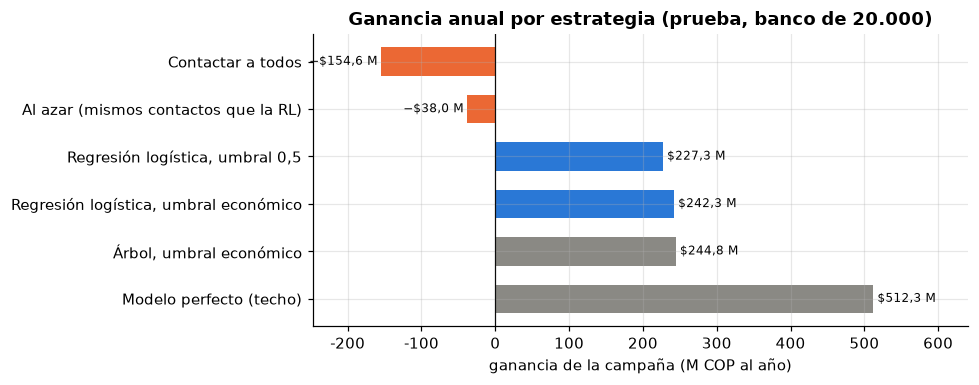

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
g = escenarios["ganancia campaña"]
colores = [C_DT if v < 0 else (C_LR if "Regresión" in k else C_GRIS) for k, v in g.items()]
ax.barh(g.index[::-1], g.values[::-1], color=colores[::-1], height=0.6)
for i, v in enumerate(g.values[::-1]):
    ax.text(v, i, tex(f" {mill(v)} "), va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=C_NEGRO, lw=0.8)
ax.xaxis.set_major_formatter(fmt_m)
ax.set(xlabel="ganancia de la campaña (M COP al año)", title="Ganancia anual por estrategia (prueba, banco de 20.000)")
ax.set_xlim(g.min() * 1.6, g.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_escenarios.png", bbox_inches="tight"); plt.show()

**Lectura de los escenarios** (prueba, banco de 20.000 clientes con 15 % de abandono)

| Estrategia | Ganancia anual | Qué muestra |
|---|---|---|
| Contactar a todos | **−COP 154,6 M** | Retiene 900 clientes (COP 630 M), pero la campaña cuesta COP 784,6 M. Con 15 % de abandono, **85 de cada 100 ofertas van a clientes que no se iban a ir**. |
| Al azar (4.910 contactos) | −COP 38,0 M | Contacta al mismo número de clientes que el modelo, pero con la precisión de la base (15 %). Prueba que el valor está en **a quién** se contacta, no en cuántos. |
| **Regresión logística, umbral económico** | **+COP 242,3 M** | Contacta al **24,5 %** de la base (4.910 clientes) con **precisión de 42,2 %**, 2,8 veces la tasa base. Retiene ≈ 621 clientes y recupera el 20,7 % del ingreso en riesgo. Cada peso gastado en la campaña devuelve 2,26 pesos (retorno de 126 %). |
| Regresión logística, umbral 0,5 | +COP 227,3 M | COP 15 M menos que con el umbral económico: contacta a 1.330 clientes más, y casi todos (≈ 1.150) son falsos positivos. |
| Árbol, umbral económico | +COP 244,8 M | Prácticamente igual a la regresión logística (diferencia de 1 %). Contacta a menos clientes (17,7 %) con más precisión (51,5 %). |
| Modelo perfecto | +COP 512,3 M | Techo teórico. El modelo elegido captura el **47 %** del valor máximo alcanzable. |

**¿Regresión logística o árbol?** En validación ganó la regresión logística (COP 246,0 M frente a 233,5 M) y en prueba el árbol (244,8 M frente a 242,3 M). Que el orden se invierta indica que la diferencia es **ruido de muestreo**. Se mantiene la regresión logística, elegida en el notebook 02, por tres razones de negocio: (1) su puntaje continuo permite ajustar el número de contactos al presupuesto, mientras que el árbol avanza a saltos; (2) sus probabilidades se pueden recalibrar para calcular el valor de cada cliente (sección 4); (3) tuvo menor brecha entre entrenamiento y validación. El árbol sigue siendo una buena alternativa si el call center tiene poca capacidad, porque logra casi la misma ganancia con un 28 % menos de contactos.

**Capacidad operativa.** Los 4.910 contactos equivalen a ≈ 818 horas de call center, es decir, unos 5 agentes de tiempo completo durante un mes.

## 4. Ganancia esperada por cada estimación

El enunciado pide la ganancia esperada **por cada estimación** del modelo. Para cada cliente $i$, el modelo entrega una probabilidad de abandono $q_i$. Si se le contacta, su valor esperado es:

$$VE_i = q_i \cdot s \cdot R \cdot H \;-\; c$$

Conviene contactarlo solo si $VE_i > 0$, es decir, si $q_i > q^* = \dfrac{c}{s \cdot R \cdot H}$.

### 4.1 Recalibración de las probabilidades

Para que $q_i$ sea una probabilidad real, hay que deshacer el efecto de `class_weight="balanced"` y llevarla a la tasa del banco. Con pesos balanceados, el modelo se comporta como si el 50 % de los clientes abandonara. La corrección es exacta en términos de *odds* (momios):

$$\text{odds}_{\text{banco}} = \text{odds}_{\text{modelo}} \cdot \frac{\pi}{1-\pi}$$

Primero se verifica en **validación**, corrigiendo hacia la tasa de ese conjunto (20,4 %): si la corrección funciona, la probabilidad corregida debe coincidir con la tasa observada en cada decil de riesgo.

In [8]:
def corregir(p, pi):
    """Lleva la probabilidad de un modelo entrenado con pesos balanceados a una población con tasa de abandono pi."""
    p = np.clip(np.asarray(p, dtype=float), 1e-9, 1 - 1e-9)
    odds = p / (1 - p) * pi / (1 - pi)
    return odds / (1 + odds)


cal = val.assign(decil=pd.qcut(val.p_lr, 10, labels=range(1, 11)), p_corregida=corregir(val.p_lr, val.churn.mean()))
tabla_cal = cal.groupby("decil", observed=True).agg(p_modelo=("p_lr", "mean"), p_corregida=("p_corregida", "mean"),
                                                    tasa_observada=("churn", "mean"))
brier = lambda p: np.mean((p - cal.churn) ** 2)
print(f"Probabilidad media: modelo {cal.p_lr.mean():.3f} | corregida {cal.p_corregida.mean():.3f} | "
      f"tasa real {cal.churn.mean():.3f}")
print(f"Error cuadrático (Brier): modelo {brier(cal.p_lr):.3f} -> corregida {brier(cal.p_corregida):.3f}")
tabla_cal.round(3)

Probabilidad media: modelo 0.398 | corregida 0.200 | tasa real 0.204
Error cuadrático (Brier): modelo 0.162 -> corregida 0.114


,p_modelo,p_corregida,tasa_observada
decil,,,
1,0.04,0.01,0.03
2,0.10,0.03,0.04
3,0.16,0.05,0.04
4,0.24,0.07,0.07
5,0.31,0.10,0.10
6,0.39,0.14,0.14
7,0.49,0.20,0.16
8,0.61,0.28,0.29
9,0.73,0.42,0.44


### 4.2 Valor esperado de cada cliente en el banco

Ahora se corrige hacia la tasa del banco (15 %) y se calcula $VE_i$ para cada cliente de prueba.

In [9]:
valor_retener = SUP["exito"] * SUP["ingreso"] * SUP["horizonte"]
q_eq = SUP["costo_contacto"] / valor_retener
odds_u = q_eq / (1 - q_eq) * (1 - SUP["churn"]) / SUP["churn"]
u_teorico = odds_u / (1 + odds_u)

t = test.assign(q=corregir(test.p_lr, SUP["churn"]))
t["valor_esperado"] = t.q * valor_retener - SUP["costo_contacto"]
t["contactar"] = t.valor_esperado > 0
# Peso de cada cliente de prueba para representar al banco (15 % de abandono, 20.000 clientes)
w1, w0 = SUP["churn"] / test.churn.mean(), (1 - SUP["churn"]) / (1 - test.churn.mean())
t["peso"] = np.where(t.churn == 1, w1, w0) * SUP["N"] / len(t)

print(f"Probabilidad de equilibrio q* = {cop(SUP['costo_contacto'])} / {cop(valor_retener)} = {q_eq:.3f}")
print(f"Umbral equivalente en la escala del modelo: {u_teorico:.2f}   (umbral elegido empíricamente en validación: {u_lr:.2f})")

esperada = (t.peso * t.valor_esperado * t.contactar).sum()
observada = (t.peso * (t.churn * valor_retener - SUP["costo_contacto"]) * t.contactar).sum()
print(f"\nGanancia de la campaña contactando solo a quienes tienen VE > 0:")
print(f"  esperada según las probabilidades del modelo: {mill(esperada)}")
print(f"  observada con los abandonos reales de prueba:  {mill(observada)}")
print(f"  por cliente evaluado: {cop(observada / SUP['N'])}  |  por cliente contactado: "
      f"{cop(observada / (t.peso * t.contactar).sum())}")

Probabilidad de equilibrio q* = $39.231 / $210.000 = 0.187
Umbral equivalente en la escala del modelo: 0.57   (umbral elegido empíricamente en validación: 0.57)

Ganancia de la campaña contactando solo a quienes tienen VE > 0:
  esperada según las probabilidades del modelo: $198,5 M
  observada con los abandonos reales de prueba:  $239,4 M
  por cliente evaluado: $11.971  |  por cliente contactado: $47.654


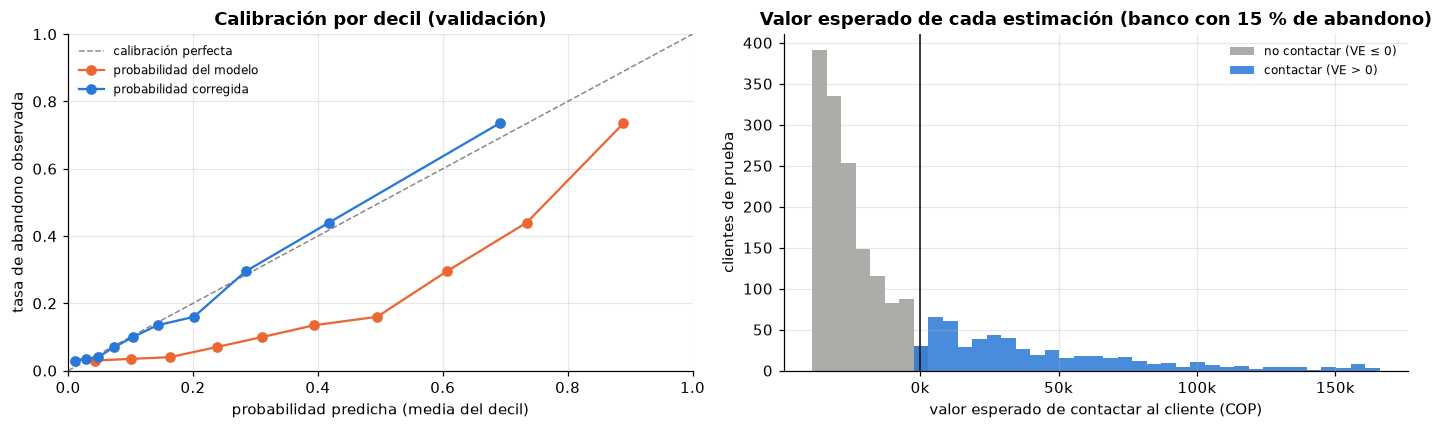

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=C_GRIS, ls="--", lw=1, label="calibración perfecta")
ax.plot(tabla_cal.p_modelo, tabla_cal.tasa_observada, "o-", color=C_DT, label="probabilidad del modelo")
ax.plot(tabla_cal.p_corregida, tabla_cal.tasa_observada, "o-", color=C_LR, label="probabilidad corregida")
ax.set(xlabel="probabilidad predicha (media del decil)", ylabel="tasa de abandono observada",
       title="Calibración por decil (validación)", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
bins = np.linspace(t.valor_esperado.min(), t.valor_esperado.max(), 40)
ax.hist(t.loc[~t.contactar, "valor_esperado"], bins=bins, color=C_GRIS, alpha=0.7, label="no contactar (VE ≤ 0)")
ax.hist(t.loc[t.contactar, "valor_esperado"], bins=bins, color=C_LR, alpha=0.85, label="contactar (VE > 0)")
ax.axvline(0, color=C_NEGRO, lw=1)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k"))
ax.set(xlabel="valor esperado de contactar al cliente (COP)", ylabel="clientes de prueba",
       title="Valor esperado de cada estimación (banco con 15 % de abandono)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_valor_por_cliente.png", bbox_inches="tight"); plt.show()

### 4.3 Ganancia por decil de riesgo

Se ordena a los clientes de mayor a menor riesgo y se agrupan en 10 deciles. Cada fila responde: *si se contacta a este grupo, ¿cuánto se gana?* Los valores se escalan al banco (20.000 clientes, 15 % de abandono) con los pesos de la sección 4.2.

In [11]:
t["decil"] = pd.qcut(-t.p_lr, 10, labels=range(1, 11))   # 1 = mayor riesgo
filas = []
for d, g in t.groupby("decil", observed=True):
    clientes = g.peso.sum()
    abandonos = (g.peso * g.churn).sum()
    filas.append({"decil": d, "rango de q": f"{g.q.min():.2f} – {g.q.max():.2f}",
                  "clientes del banco": clientes, "tasa de abandono real (%)": abandonos / clientes * 100,
                  "VE medio por cliente (COP)": g.valor_esperado.mean(),
                  "ganancia real del decil (M COP)": (abandonos * valor_retener - clientes * SUP["costo_contacto"]) / 1e6})
deciles = pd.DataFrame(filas).set_index("decil")
deciles["ganancia acumulada (M COP)"] = deciles["ganancia real del decil (M COP)"].cumsum()
deciles["lift"] = deciles["tasa de abandono real (%)"] / (SUP["churn"] * 100)
deciles.round(1)

,rango de q,clientes del banco,tasa de abandono real (%),VE medio por cliente (COP),ganancia real del decil (M COP),ganancia acumulada (M COP),lift
decil,,,,,,,
1,0.41 – 0.98,"1,612.80",72.20,"85,561.90",181.30,181.30,4.80
2,0.25 – 0.40,"1,830.70",37.00,"28,609.00",70.60,251.90,2.50
3,0.17 – 0.25,"1,992.40",15.90,"4,972.20",-11.60,240.30,1.10
4,0.12 – 0.17,"2,015.50",13.20,"-9,083.10",-23.30,216.90,0.90
5,0.08 – 0.12,"2,065.00",7.50,"-18,933.10",-48.50,168.40,0.50
6,0.06 – 0.08,"2,065.00",7.50,"-24,992.70",-48.50,119.90,0.50
7,0.04 – 0.06,"2,094.70",4.20,"-29,032.10",-63.60,56.30,0.30
8,0.03 – 0.04,"2,104.60",3.20,"-32,338.80",-68.60,-12.30,0.20
9,0.01 – 0.03,"2,104.60",3.20,"-35,003.60",-68.60,-81.00,0.20


In [12]:
casos = t.sort_values("q").iloc[[int(len(t) * f) for f in (0.99, 0.90, 0.80, 0.70, 0.50, 0.10)]]
pd.DataFrame({
    "p del modelo": casos.p_lr.round(3), "q en el banco": casos.q.round(3),
    "valor esperado (COP)": casos.valor_esperado.map(cop),
    "decisión": np.where(casos.contactar, "contactar", "no contactar"),
    "¿abandonó?": np.where(casos.churn == 1, "sí", "no"),
}).set_index(pd.Index(casos.id.values, name="cliente (id)"))

,p del modelo,q en el banco,valor esperado (COP),decisión,¿abandonó?
cliente (id),,,,,
9544,0.97,0.86,$140.530,contactar,sí
1053,0.80,0.41,$45.981,contactar,no
2399,0.66,0.26,$14.272,contactar,no
4848,0.54,0.17,−$3.056,no contactar,no
2990,0.33,0.08,−$22.731,no contactar,no
4367,0.08,0.01,−$36.207,no contactar,no


**Lectura: ganancia esperada por cada estimación**

- **La recalibración funciona.** La probabilidad media corregida (0,200) coincide con la tasa real (0,204), el error de Brier baja de 0,162 a 0,114 y las probabilidades corregidas coinciden con lo observado en cada decil.
- **Regla de decisión por cliente:** contactar si su probabilidad de abandonar en el banco supera **$q^* = 0{,}187$**. En la escala del modelo equivale al umbral **0,57**, que es **exactamente el mismo** que se encontró buscando el máximo en validación (sección 3.1). Que dos caminos independientes, la teoría y la búsqueda empírica, lleguen al mismo umbral respalda el análisis.
- **Ganancia por estimación.** Contactando solo a los clientes con valor esperado positivo, la campaña gana COP 239,4 M en prueba: **≈ COP 12.000 por cada cliente evaluado** y ≈ COP 47.700 por cada cliente contactado. Las probabilidades del modelo anticipaban COP 198,5 M; es decir, el modelo es **algo conservador** (en el decil de mayor riesgo predice 0,69 y se observa 0,73), así que las proyecciones basadas en él son prudentes.
- **El valor está muy concentrado.** El decil de mayor riesgo (≈ 1.600 clientes, el 8 % del banco) tiene 72 % de abandono, 4,8 veces la tasa base. Cada cliente de ese decil vale en promedio **+COP 85.600** y el decil aporta COP 181 M, el **75 % de la ganancia**. El segundo decil aporta COP 71 M más. El tercero (q entre 0,17 y 0,25) está en la frontera del equilibrio, y del cuarto en adelante cada contacto pierde dinero. Contactar los 10 deciles equivale a contactar a todos (−COP 154,6 M).
- **Casos individuales.** La última tabla muestra la decisión para clientes de distinto nivel de riesgo. Para un cliente del percentil 99 de riesgo ($q$ = 0,86), el contacto vale ≈ COP 140.500. Para el del percentil 70 ($q$ = 0,17, apenas bajo el umbral de 0,187), el valor esperado ya es ligeramente negativo (−COP 3.100). Para un cliente de riesgo mediano ($q$ = 0,08), contactarlo **costaría** ≈ COP 22.700 netos.

## 5. Inversión y punto de equilibrio

La ganancia de la campaña todavía no descuenta lo que cuesta **tener** el modelo: la inversión inicial ($F$ ≈ COP 102,5 M) y la operación anual ($O$ ≈ COP 42,8 M). Se usa la regresión logística con su umbral económico (elegido en validación, medido en prueba).

$$\text{Beneficio neto anual} = \text{Ganancia de la campaña} - O \qquad \text{Meses para recuperar la inversión} = \frac{F}{\text{Beneficio neto anual}/12}$$

In [13]:
def resultado(**cambios):
    """Ganancia y retorno de la inversión con la RL, re-optimizando el umbral en validación para cada escenario."""
    s = {**SUP, **cambios}
    u = umbral_optimo(val.churn, val.p_lr, **cambios)
    g = economia(*tasas(test.churn, test.p_lr, u), **cambios)["ganancia campaña"]
    neto = g - s["costo_oper"]
    return {"umbral": u, "ganancia campaña": g, "beneficio neto anual": neto,
            "beneficio año 1": neto - s["costo_impl"],
            "meses para recuperar": s["costo_impl"] / (neto / 12) if neto > 0 else np.inf}


base = resultado()
g_cliente = base["ganancia campaña"] / SUP["N"]
pd.Series({
    "Ganancia anual de la campaña": mill(base["ganancia campaña"]),
    "− Costo de operación anual": mill(SUP["costo_oper"]),
    "= Beneficio neto anual": mill(base["beneficio neto anual"]),
    "− Inversión inicial": mill(SUP["costo_impl"]),
    "= Beneficio del primer año": mill(base["beneficio año 1"]),
    "Meses para recuperar la inversión": f"{base['meses para recuperar']:.1f}",
    "Retorno sobre la inversión a 3 años": f"{(3 * base['beneficio neto anual'] - SUP['costo_impl']) / SUP['costo_impl']:.1f}x",
    "Base mínima para cubrir la operación": f"{SUP['costo_oper'] / g_cliente:,.0f} clientes",
    "Base mínima para recuperar todo en el año 1": f"{(SUP['costo_oper'] + SUP['costo_impl']) / g_cliente:,.0f} clientes",
}, name="Regresión logística").to_frame()

,Regresión logística
Ganancia anual de la campaña,"$242,3 M"
− Costo de operación anual,"$42,8 M"
= Beneficio neto anual,"$199,6 M"
− Inversión inicial,"$102,5 M"
= Beneficio del primer año,"$97,1 M"
Meses para recuperar la inversión,6.2
Retorno sobre la inversión a 3 años,4.8x
Base mínima para cubrir la operación,"3,528 clientes"
Base mínima para recuperar todo en el año 1,"11,987 clientes"


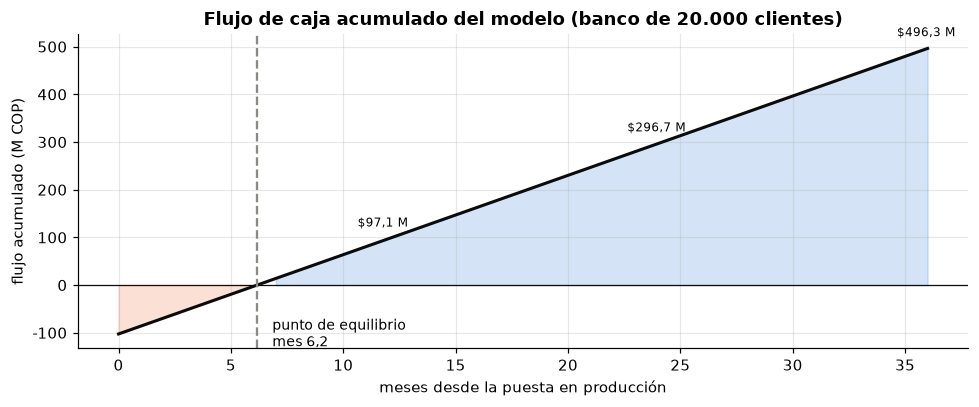

In [14]:
meses = np.arange(0, 37)
flujo = -SUP["costo_impl"] + meses * base["beneficio neto anual"] / 12
m_eq = base["meses para recuperar"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(meses, flujo, 0, where=flujo < 0, color=C_DT, alpha=0.2)
ax.fill_between(meses, flujo, 0, where=flujo >= 0, color=C_LR, alpha=0.2)
ax.plot(meses, flujo, color=C_NEGRO, lw=2)
ax.axhline(0, color=C_NEGRO, lw=0.8)
ax.axvline(m_eq, color=C_GRIS, ls="--")
ax.annotate(f"punto de equilibrio\nmes {m_eq:.1f}".replace(".", ","), (m_eq, 0), xytext=(10, -40), textcoords="offset points", fontsize=9)
for m in (12, 24, 36):
    ax.annotate(tex(mill(flujo[m])), (m, flujo[m]), xytext=(-20, 8), textcoords="offset points", fontsize=8)
ax.yaxis.set_major_formatter(fmt_m)
ax.set(xlabel="meses desde la puesta en producción", ylabel="flujo acumulado (M COP)",
       title="Flujo de caja acumulado del modelo (banco de 20.000 clientes)")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_break_even.png", bbox_inches="tight"); plt.show()

### 5.1 Punto de equilibrio en cada supuesto

Además del tiempo, interesa saber **hasta dónde puede empeorar cada supuesto** antes de que el modelo deje de ser rentable. Se mueve un parámetro a la vez (el umbral se re-optimiza en validación en cada caso) y se busca dónde el beneficio neto anual cruza cero.

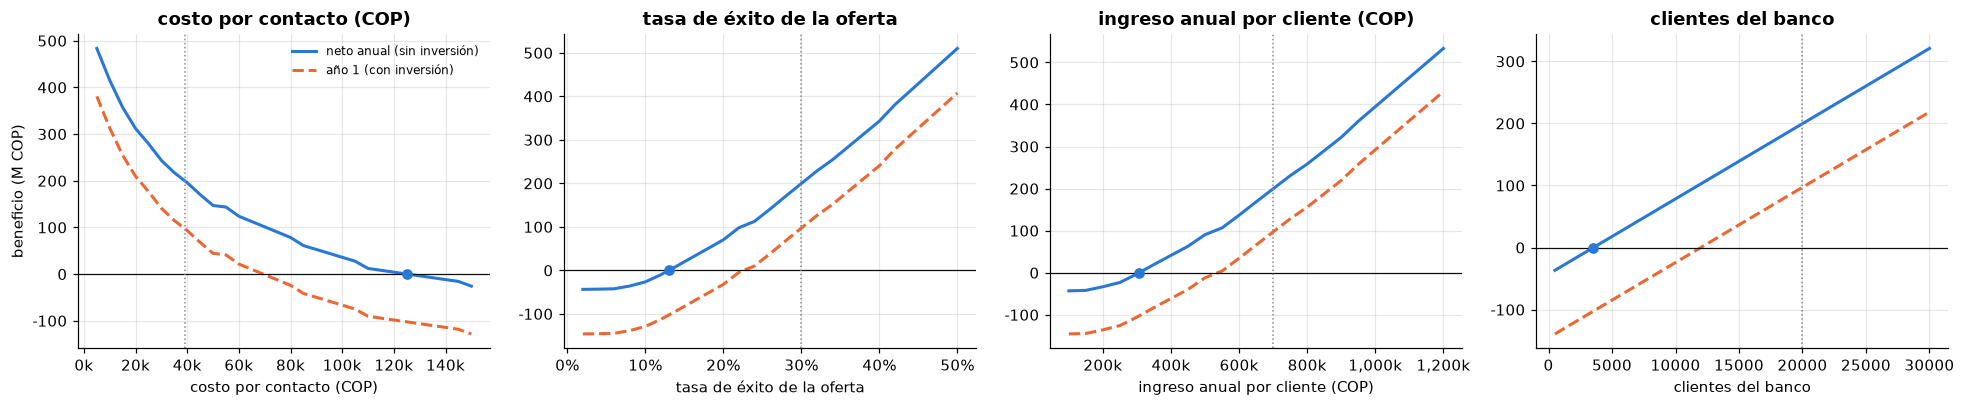

,valor base,equilibrio operativo,equilibrio con inversión (año 1)
costo por contacto (COP),$39.231,$125.274,$69.448
tasa de éxito de la oferta,30.0%,13.0%,22.6%
ingreso anual por cliente (COP),$700.000,$306.493,$537.206
clientes del banco,"20,000","3,528","11,987"


In [15]:
def cruce(x, y):
    """Primer valor de x donde y cambia de signo (interpolación lineal)."""
    y = np.asarray(y)
    i = np.where(np.sign(y[:-1]) != np.sign(y[1:]))[0]
    if len(i) == 0:
        return np.nan
    i = i[0]
    return x[i] - y[i] * (x[i + 1] - x[i]) / (y[i + 1] - y[i])


rejillas = {
    "costo_contacto": (np.linspace(5_000, 150_000, 30), "costo por contacto (COP)", lambda v: cop(v)),
    "exito": (np.linspace(0.02, 0.50, 25), "tasa de éxito de la oferta", lambda v: f"{v:.1%}"),
    "ingreso": (np.linspace(100_000, 1_200_000, 23), "ingreso anual por cliente (COP)", lambda v: cop(v)),
    "N": (np.linspace(500, 30_000, 30), "clientes del banco", lambda v: f"{v:,.0f}"),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
equilibrios = {}
for ax, (par, (xs, etiqueta, fmt)) in zip(axes, rejillas.items()):
    res = pd.DataFrame([resultado(**{par: x}) for x in xs], index=xs)
    ax.plot(xs, res["beneficio neto anual"], color=C_LR, lw=2, label="neto anual (sin inversión)")
    ax.plot(xs, res["beneficio año 1"], color=C_DT, lw=2, ls="--", label="año 1 (con inversión)")
    ax.axhline(0, color=C_NEGRO, lw=0.8)
    ax.axvline(SUP[par], color=C_GRIS, ls=":", lw=1)
    x0 = cruce(xs, res["beneficio neto anual"])
    x1 = cruce(xs, res["beneficio año 1"])
    equilibrios[etiqueta] = {"valor base": fmt(SUP[par]), "equilibrio operativo": fmt(x0),
                             "equilibrio con inversión (año 1)": fmt(x1)}
    if not np.isnan(x0):
        ax.scatter([x0], [0], color=C_LR, zorder=3)
    ax.yaxis.set_major_formatter(fmt_m)
    if par in ("costo_contacto", "ingreso"):
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    elif par == "exito":
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set(xlabel=etiqueta, title=etiqueta)
axes[0].set_ylabel("beneficio (M COP)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_equilibrio_parametros.png", bbox_inches="tight"); plt.show()
pd.DataFrame(equilibrios).T

**Lectura del punto de equilibrio**

- Después de pagar la operación del modelo (COP 42,8 M al año), el banco gana **COP 199,6 M netos al año**. La inversión inicial de COP 102,5 M se recupera en **6,2 meses** desde la puesta en producción. Como el desarrollo toma ≈ 5 meses, el proyecto queda en equilibrio unos **11 meses después de iniciado**. A 3 años, el retorno es de **4,8 veces la inversión**.
- **Tamaño mínimo del banco.** Con estos supuestos, el modelo cubre su operación desde **≈ 3.500 clientes** y recupera toda la inversión dentro del primer año desde **≈ 12.000 clientes**. Un banco de 20.000 clientes está holgadamente por encima.
- **¿Hasta dónde pueden empeorar los supuestos?** El beneficio neto anual sigue siendo positivo mientras:
  - el costo por contacto no supere **≈ COP 125.000** (3,2 veces el valor base);
  - la oferta convenza al menos al **13 %** de los que iban a abandonar (frente al 30 % supuesto);
  - el ingreso anual por cliente sea mayor a **≈ COP 306.000** (frente a 700.000).

  Para recuperar además la inversión en el primer año, los límites son más estrechos: costo por contacto ≤ COP 69.400, éxito ≥ **22,6 %** e ingreso ≥ COP 537.000.
- **El supuesto más frágil es el éxito de la oferta.** El 30 % viene del enunciado y no hay datos del banco que lo respalden; basta con que sea 22,6 % para que el primer año quede en cero. Por eso la recomendación final incluye medirlo con un piloto.

## 6. Análisis de sensibilidad paramétrico

### 6.1 Un supuesto a la vez (gráfico de tornado)

Cada barra muestra cómo cambia el **beneficio del primer año** (incluida la inversión) cuando un supuesto pasa de su valor bajo a su valor alto, con el resto en su valor base.

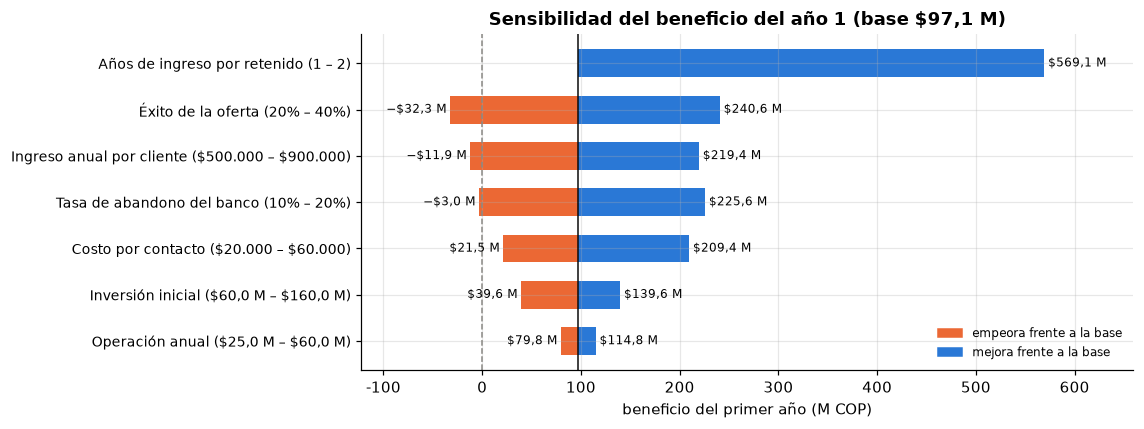

,"año 1, bajo (M COP)","año 1, alto (M COP)",meses (bajo),meses (alto)
supuesto,,,,
Años de ingreso por retenido (1 – 2),97.10,569.10,6.20,1.80
Éxito de la oferta (20% – 40%),-32.30,240.60,17.50,3.60
Ingreso anual por cliente ($500.000 – $900.000),-11.90,219.40,13.60,3.80
Tasa de abandono del banco (10% – 20%),-3.00,225.60,12.40,3.70
Costo por contacto ($20.000 – $60.000),209.40,21.50,3.90,9.90
"Inversión inicial ($60,0 M – $160,0 M)",139.60,39.60,3.60,9.60
"Operación anual ($25,0 M – $60,0 M)",114.80,79.80,5.70,6.70


In [16]:
rangos = {
    "ingreso": (500_000, 900_000, "Ingreso anual por cliente", cop),
    "exito": (0.20, 0.40, "Éxito de la oferta", lambda v: f"{v:.0%}"),
    "costo_contacto": (20_000, 60_000, "Costo por contacto", cop),
    "churn": (0.10, 0.20, "Tasa de abandono del banco", lambda v: f"{v:.0%}"),
    "horizonte": (1, 2, "Años de ingreso por retenido", lambda v: f"{v:.0f}"),
    "costo_impl": (60e6, 160e6, "Inversión inicial", mill),
    "costo_oper": (25e6, 60e6, "Operación anual", mill),
}
filas = []
for par, (lo, hi, nombre, fmt) in rangos.items():
    r_lo, r_hi = resultado(**{par: lo}), resultado(**{par: hi})
    filas.append({"supuesto": f"{nombre} ({fmt(lo)} – {fmt(hi)})",
                  "año 1 con valor bajo": r_lo["beneficio año 1"], "año 1 con valor alto": r_hi["beneficio año 1"],
                  "meses (bajo)": r_lo["meses para recuperar"], "meses (alto)": r_hi["meses para recuperar"]})
tornado = pd.DataFrame(filas).set_index("supuesto")
tornado["amplitud"] = (tornado["año 1 con valor alto"] - tornado["año 1 con valor bajo"]).abs()
tornado = tornado.sort_values("amplitud")

from matplotlib.patches import Patch

b1 = base["beneficio año 1"]
fig, ax = plt.subplots(figsize=(10.5, 4))
for i, (nombre, r) in enumerate(tornado.iterrows()):
    for v in (r["año 1 con valor bajo"], r["año 1 con valor alto"]):
        if np.isclose(v, b1):
            continue
        ax.barh(i, v - b1, left=b1, color=C_LR if v > b1 else C_DT, height=0.6)
        ax.text(v, i, tex(f" {mill(v)} "), va="center", ha="left" if v > b1 else "right", fontsize=8)
ax.axvline(b1, color=C_NEGRO, lw=1)
ax.axvline(0, color=C_GRIS, ls="--", lw=1)
ax.set_yticks(range(len(tornado))); ax.set_yticklabels([tex(s) for s in tornado.index], fontsize=9)
ax.xaxis.set_major_formatter(fmt_m)
ax.set_xlim(min(0, tornado[["año 1 con valor bajo", "año 1 con valor alto"]].values.min()) - 90e6,
            tornado[["año 1 con valor bajo", "año 1 con valor alto"]].values.max() + 90e6)
ax.set(xlabel="beneficio del primer año (M COP)", title=tex(f"Sensibilidad del beneficio del año 1 (base {mill(b1)})"))
ax.legend(handles=[Patch(color=C_DT, label="empeora frente a la base"), Patch(color=C_LR, label="mejora frente a la base")],
          frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_tornado.png", bbox_inches="tight"); plt.show()

vista = tornado.drop(columns="amplitud").iloc[::-1].copy()
vista[["año 1 con valor bajo", "año 1 con valor alto"]] /= 1e6
vista.rename(columns={"año 1 con valor bajo": "año 1, bajo (M COP)", "año 1 con valor alto": "año 1, alto (M COP)"}).round(1)

### 6.2 Ingreso por cliente × costo por contacto

Son los dos supuestos con más incertidumbre del lado del banco. La tabla muestra la **ganancia anual de la campaña** (M COP) para cada combinación, con el umbral re-optimizado en cada celda.

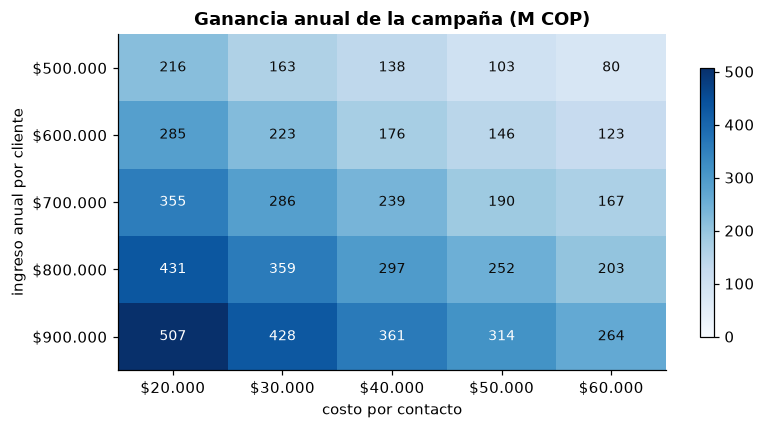

In [17]:
ingresos = np.arange(500_000, 900_001, 100_000)
costos = np.arange(20_000, 60_001, 10_000)
mapa = pd.DataFrame([[resultado(ingreso=r, costo_contacto=c)["ganancia campaña"] / 1e6 for c in costos] for r in ingresos],
                    index=[cop(r) for r in ingresos], columns=[cop(c) for c in costos])

fig, ax = plt.subplots(figsize=(7.5, 4))
norma = (TwoSlopeNorm(vcenter=0, vmin=mapa.values.min(), vmax=mapa.values.max()) if mapa.values.min() < 0
         else plt.Normalize(0, mapa.values.max()))
im = ax.imshow(mapa.values, cmap="RdBu" if mapa.values.min() < 0 else "Blues", norm=norma, aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 * mapa.values.max() else C_NEGRO)
ax.set_xticks(range(len(costos))); ax.set_xticklabels([tex(c) for c in mapa.columns])
ax.set_yticks(range(len(ingresos))); ax.set_yticklabels([tex(r) for r in mapa.index])
ax.set(xlabel="costo por contacto", ylabel="ingreso anual por cliente", title="Ganancia anual de la campaña (M COP)")
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_mapa_ingreso_costo.png", bbox_inches="tight"); plt.show()

### 6.3 Todos los supuestos a la vez (Monte Carlo)

Se simulan 5.000 escenarios en los que **todos los supuestos varían al mismo tiempo** dentro de sus rangos. También se incluye la incertidumbre del propio modelo: en cada escenario se remuestrea el conjunto de prueba (*bootstrap*), lo que cambia el TPR y el FPR. El umbral queda fijo en el de la base, como lo haría el banco en la práctica.

| Supuesto | Distribución |
|---|---|
| Ingreso anual por cliente | Uniforme entre COP 500.000 y 900.000 |
| Éxito de la oferta | Triangular (20 %, 30 %, 40 %) |
| Costo por contacto | Triangular (COP 20.000, 39.200, 60.000) |
| Tasa de abandono del banco | Uniforme entre 10 % y 20 % |
| Inversión inicial | Triangular (COP 60 M, 102,5 M, 160 M) |
| Operación anual | Triangular (COP 25 M, 42,8 M, 60 M) |

In [18]:
n_sim = 5_000
u_base = base["umbral"]
y_t, contactar_t = test.churn.values, (test.p_lr.values >= u_base)
tpr_b, fpr_b = np.empty(n_sim), np.empty(n_sim)
for k in range(n_sim):
    i = rng.integers(0, len(y_t), len(y_t))
    yb, cb = y_t[i], contactar_t[i]
    tpr_b[k], fpr_b[k] = cb[yb == 1].mean(), cb[yb == 0].mean()

R = rng.uniform(500_000, 900_000, n_sim)
s_ = rng.triangular(0.20, 0.30, 0.40, n_sim)
c_ = rng.triangular(20_000, SUP["costo_contacto"], 60_000, n_sim)
pi = rng.uniform(0.10, 0.20, n_sim)
F = rng.triangular(60e6, SUP["costo_impl"], 160e6, n_sim)
O = rng.triangular(25e6, SUP["costo_oper"], 60e6, n_sim)

N = SUP["N"]
vp, fp = N * pi * tpr_b, N * (1 - pi) * fpr_b
G = vp * s_ * R - (vp + fp) * c_
neto = G - O
anio1 = neto - F
meses_mc = np.where(neto > 0, F / (neto / 12), np.inf)

mc = pd.DataFrame({"ganancia campaña (M COP)": G / 1e6, "beneficio neto anual (M COP)": neto / 1e6,
                   "beneficio año 1 (M COP)": anio1 / 1e6, "meses para recuperar": meses_mc})
resumen_mc = mc.quantile([0.05, 0.25, 0.50, 0.75, 0.95]).T   # inf = el escenario nunca recupera la inversión
resumen_mc.columns = ["P5", "P25", "mediana", "P75", "P95"]
display(resumen_mc.round(1))
print(f"Probabilidad de que la campaña gane dinero:              {(G > 0).mean():.1%}")
print(f"Probabilidad de que el beneficio neto anual sea positivo: {(neto > 0).mean():.1%}")
print(f"Probabilidad de recuperar la inversión en el primer año:  {(anio1 > 0).mean():.1%}")
print(f"Probabilidad de recuperarla en 24 meses o menos:          {(meses_mc <= 24).mean():.1%}")

,P5,P25,mediana,P75,P95
ganancia campaña (M COP),57.00,147.40,228.00,318.60,470.30
beneficio neto anual (M COP),15.10,105.50,185.70,276.60,427.60
beneficio año 1 (M COP),-97.70,-3.80,78.10,169.30,320.40
meses para recuperar,2.80,4.60,6.90,12.40,82.80


Probabilidad de que la campaña gane dinero:              99.3%
Probabilidad de que el beneficio neto anual sea positivo: 96.7%
Probabilidad de recuperar la inversión en el primer año:  73.8%
Probabilidad de recuperarla en 24 meses o menos:          88.2%


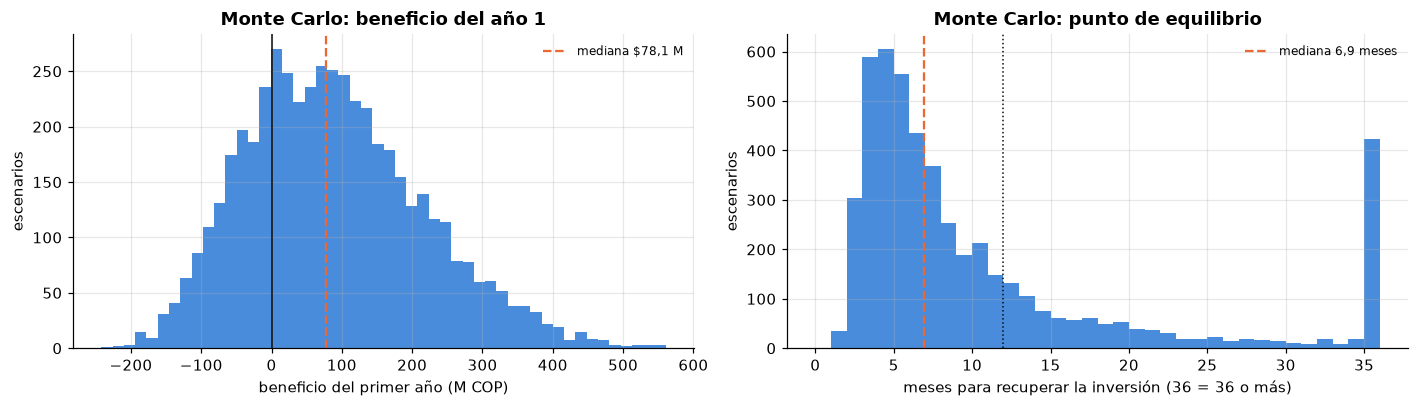

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.hist(anio1 / 1e6, bins=50, color=C_LR, alpha=0.85)
ax.axvline(0, color=C_NEGRO, lw=1)
ax.axvline(np.median(anio1) / 1e6, color=C_DT, ls="--", label=tex(f"mediana {mill(np.median(anio1))}"))
ax.set(xlabel="beneficio del primer año (M COP)", ylabel="escenarios", title="Monte Carlo: beneficio del año 1")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.hist(np.clip(meses_mc, 0, 36), bins=36, range=(0, 36), color=C_LR, alpha=0.85)
ax.axvline(12, color=C_NEGRO, lw=1, ls=":")
ax.axvline(np.median(meses_mc), color=C_DT, ls="--", label=f"mediana {np.median(meses_mc):.1f} meses".replace(".", ","))
ax.set(xlabel="meses para recuperar la inversión (36 = 36 o más)", ylabel="escenarios", title="Monte Carlo: punto de equilibrio")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_montecarlo.png", bbox_inches="tight"); plt.show()

**Lectura del análisis de sensibilidad**

- **Tornado.** El supuesto que más mueve el resultado es el **horizonte**: si un cliente retenido se queda 2 años en vez de 1, el beneficio del primer año pasa de COP 97 M a COP 569 M. Esto muestra que el supuesto base de 1 año es muy conservador. Le siguen el **éxito de la oferta**, el **ingreso por cliente**, la **tasa de abandono** y el **costo por contacto**. Los costos del propio modelo (inversión y operación) son los que menos pesan.
- Solo tres extremos dejan el **primer año** en negativo: éxito de 20 % (−COP 32 M), ingreso de COP 500.000 (−COP 12 M) y abandono de 10 % (−COP 3 M). En los tres el beneficio neto anual sigue siendo positivo y la inversión se recupera en 12–18 meses.
- **Ingreso × costo por contacto.** El mapa muestra que la campaña es rentable incluso en la combinación más desfavorable (ingreso de COP 500.000 y contacto de COP 60.000), porque el umbral se ajusta: cuando contactar es más caro, el modelo contacta a menos clientes y solo a los de mayor riesgo.
- **Monte Carlo (todos los supuestos a la vez, más la incertidumbre del modelo):**
  - la campaña gana dinero en el **99,3 %** de los escenarios;
  - el beneficio neto anual es positivo en el **96,7 %**;
  - la inversión se recupera en el primer año en el **73,8 %** y en 24 meses o menos en el **88,2 %**;
  - en el escenario típico (mediana), el beneficio del primer año es COP 78 M y la inversión se recupera en 6,9 meses. En el 5 % de escenarios más desfavorables, el primer año pierde más de COP 98 M y la recuperación tarda más de 80 meses (≈ 7 años) o no llega nunca.
- **Conclusión:** el modelo es rentable en casi cualquier combinación razonable de supuestos. El riesgo principal no es el modelo, sino la **efectividad real de la oferta**.

## 7. Limitaciones

**Del modelo y sus datos**

1. **Clientes europeos, banco colombiano.** El modelo se entrenó con clientes de Francia, Alemania y España. Los patrones (por ejemplo, el efecto del país o del género) pueden no trasladarse a Colombia. Hay que reentrenarlo con datos del banco antes de usarlo en producción.
2. **Datos con señales de ser sintéticos.** `estimated_salary` es uniforme entre 0 y 200.000 y había valores imposibles (edad 210). Las métricas podrían ser distintas con datos reales.
3. **Perfil estático.** El modelo solo ve variables demográficas y de producto. No tiene transacciones, quejas, PQRS ni uso de canales, por eso falla con jóvenes y con clientes de 2 productos (notebook 02). Esta es la principal razón por la que captura el 47 % del valor de un modelo perfecto y no más.
4. **Sin dimensión temporal.** El dataset es un solo corte: no se sabe **cuándo** abandona el cliente ni con cuánta anticipación lo detecta el modelo. En producción, el comportamiento cambia (deriva) y hay que reentrenar periódicamente; ese costo está incluido en la operación.
5. **Tamaño de la prueba.** Las cifras salen de 2.000 clientes (407 abandonos). La incertidumbre de muestreo se incluyó en el Monte Carlo mediante *bootstrap*.
6. **Variables sensibles.** El modelo usa género y país. Aunque el uso es para ofrecer un beneficio, debe revisarlo el área de cumplimiento.

**Del cálculo de valor**

7. **Cambio de la tasa de abandono.** Se supone que al pasar de 20,4 % a 15 % solo cambia **cuántos** clientes abandonan, no **cómo son**. Si los clientes colombianos que abandonan tienen otro perfil, el TPR y el FPR cambiarían.
8. **Éxito uniforme de la oferta.** Se asume que la oferta convence al 30 % de cualquier cliente que iba a abandonar. En la realidad varía por segmento. Además, el modelo predice **riesgo**, no **quién responde a la oferta**: un modelo de *uplift* con grupo de control lo mediría. Contactar a algunos clientes podría incluso **provocar** su salida.
9. **El incentivo se paga a todos los contactados**, incluidos ≈ 2.840 falsos positivos que se iban a quedar. Es lo que pide el enunciado y hace el cálculo conservador. Si el incentivo solo se pagara al aceptarlo, la ganancia sería mayor.
10. **Horizonte de un año y sin valor de vida del cliente.** No se cuentan los años siguientes del cliente retenido, las ventas cruzadas ni el costo de adquisición que se evita. Tampoco se descuenta el dinero en el tiempo, lo que es poco relevante con una recuperación menor a un año.
11. **Costos de fuentes de mercado, no cotizaciones.** Los costos de contacto e implementación vienen de guías de proveedores y salariales. El análisis de sensibilidad cubre rangos amplios, pero deberían reemplazarse por cotizaciones reales del banco.
12. **Una campaña al año.** En la práctica conviene puntuar a los clientes cada mes, lo que permitiría actuar antes y probablemente aumentaría el éxito de la oferta.

## 8. Insights y recomendación (Entregable 6)

### Resumen ejecutivo

**Para un banco de 20.000 clientes, el modelo de FinAlpes genera ≈ COP 242 M al año en ingresos retenidos, ya descontado el costo de la campaña. La inversión de ≈ COP 100 M se recupera en unos 6 meses de operación.**

### Hallazgos

1. **Sin modelo, la campaña de retención destruye valor.** Contactar a todos los clientes pierde COP 155 M al año: con 15 % de abandono, 85 de cada 100 ofertas van a clientes que no se iban a ir. El valor no está en hacer la campaña, sino en **a quién** se le hace.
2. **El modelo convierte esa pérdida en ganancia.** Contactando al 24,5 % de clientes con mayor riesgo, la precisión sube de 15 % a 42 % y la campaña gana COP 242 M (cada peso invertido en ella devuelve 2,26). Después de pagar la operación del modelo quedan ≈ COP 200 M netos al año.
3. **El valor se concentra en pocos clientes.** El 8 % de clientes con mayor riesgo (≈ 1.600, de los cuales el 72 % abandona) aporta el 75 % de la ganancia. Si el presupuesto es limitado, hay que empezar por ellos.
4. **La regla de decisión es simple:** contactar a un cliente solo si su probabilidad real de abandono supera el **18,7 %**, que es el costo del contacto dividido por el valor de retenerlo. Si cambian los costos o el ingreso, la regla se ajusta sola.
5. **Quiénes son los clientes en riesgo** (notebook 02): los que tienen 3–4 productos (más de 80 % abandona) o un solo producto, los de 45–60 años, los inactivos y las mujeres, además de la región con mayor abandono (Alemania en los datos). Los clientes con **2 productos** son los más leales.
6. **El resultado es robusto.** El modelo gana dinero en el 99 % de 5.000 escenarios simulados y recupera la inversión en menos de 2 años en el 88 %. El supuesto crítico es la efectividad de la oferta: si convence a menos del 13 % de los clientes en riesgo, la campaña no alcanza a pagar la operación del modelo.
7. **Hay mucho margen de mejora.** El modelo captura el 47 % del valor de un modelo perfecto (COP 512 M). Agregar datos de transacciones y quejas (PQRS) podría cerrar parte de esa brecha.

### Recomendación final

**Implementar el modelo, empezando con un piloto controlado:**

1. **Piloto de 3 meses.** Puntuar la base, contactar al decil de mayor riesgo y dejar un **grupo de control** aleatorio sin contactar. Así se mide el éxito real de la oferta, que es el supuesto más crítico.
2. **Reentrenar con datos del banco colombiano** antes de escalar, porque el modelo actual aprendió de clientes europeos.
3. **Diseñar ofertas por segmento:** venta cruzada de un segundo producto para quienes tienen uno solo; revisión de cobros y experiencia para quienes tienen 3–4; reactivación para los inactivos.
4. **Escalar al umbral económico** (≈ 25 % de la base) si el piloto confirma un éxito de al menos ≈ 23 %, el nivel con el que la inversión se recupera en el primer año.
5. **Enriquecer el modelo** con datos de comportamiento y **revisar con cumplimiento** el uso del género como variable.

In [20]:
resumen = pd.DataFrame({
    "valor": [mill(escenarios.loc[RL_OPT, "ganancia campaña"]), mill(escenarios.loc["Contactar a todos", "ganancia campaña"]),
              f"{escenarios.loc[RL_OPT, '% de la base']:.1f} %", cop(observada / SUP["N"]),
              mill(base["beneficio neto anual"]), f"{base['meses para recuperar']:.1f}",
              f"{(G > 0).mean():.1%}"]},
    index=["Ganancia anual de la campaña con el modelo", "Ganancia anual contactando a todos",
           "Clientes contactados", "Ganancia por cliente evaluado",
           "Beneficio neto anual (descontada la operación)", "Meses para recuperar la inversión",
           "Probabilidad de ganar dinero (Monte Carlo)"])
resumen.to_csv("../reports/resumen_valor.csv", encoding="utf-8")
resumen

,valor
Ganancia anual de la campaña con el modelo,"$242,3 M"
Ganancia anual contactando a todos,"−$154,6 M"
Clientes contactados,24.5 %
Ganancia por cliente evaluado,$11.971
Beneficio neto anual (descontada la operación),"$199,6 M"
Meses para recuperar la inversión,6.2
Probabilidad de ganar dinero (Monte Carlo),99.3%
